# Лабораторная работа №2
## Раздел 1.2: Модели машинного обучения Scikit-learn и CatBoost
**Студент:** Мустафаев Музаффар

*Для оптимизации вычислений многомерных рядов применяется снижение размерности PCA (50 компонент, сохраняющих 96.5% дисперсии).*


### Задания 1.2.1 – 1.2.4. Создание, обучение и оценка точности моделей
Создать модели Scikit-learn и CatBoost, разделить наборы на train/test и вывести конечную точность.


=== РЕЗУЛЬТАТЫ КЛАССИФИКАЦИИ: НАБОР ФКГ ===
                       Model  Train_Acc  Test_Acc
Stochastic Gradient Boosting   1.000000    0.6625
           Gradient Boosting   1.000000    0.6625
                RandomForest   1.000000    0.6475
         k-nearest Neighbors   0.727500    0.6450
                    CatBoost   0.818125    0.6350
               Decision Tree   0.814375    0.5325
      Support Vector Machine   0.491875    0.4975

=== РЕЗУЛЬТАТЫ КЛАССИФИКАЦИИ: МОДУЛЬ ПОЗИЦИОНИРОВАНИЯ ===
                       Model  Train_Acc  Test_Acc
Stochastic Gradient Boosting   1.000000  0.880556
           Gradient Boosting   1.000000  0.880556
                RandomForest   1.000000  0.827778
                    CatBoost   0.911806  0.777778
      Support Vector Machine   0.890972  0.758333
         k-nearest Neighbors   0.843056  0.747222
               Decision Tree   0.793750  0.666667


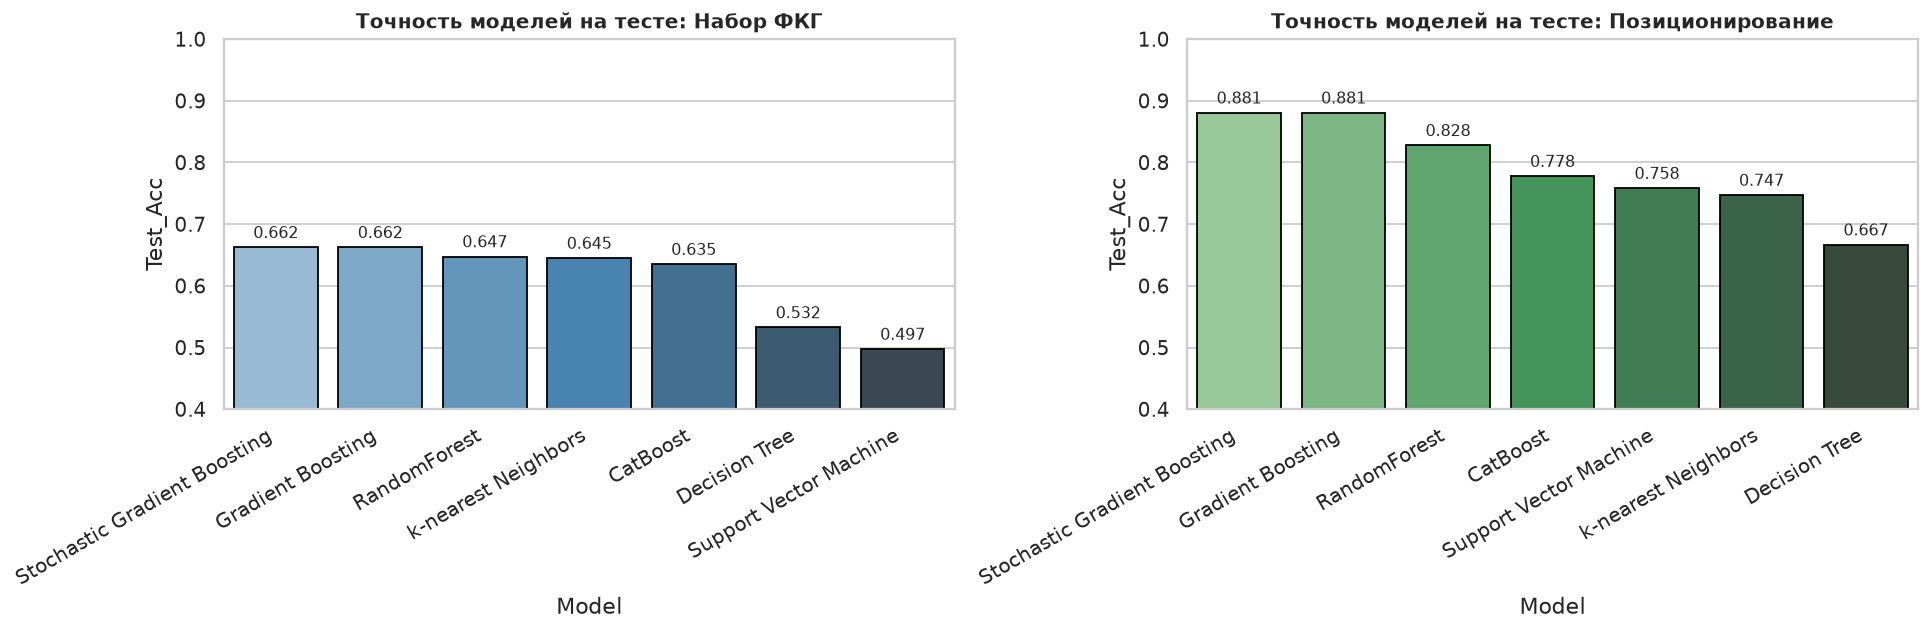

In [13]:
# Ответ на задание 1.2.4: Точность моделей машинного обучения
print("=== РЕЗУЛЬТАТЫ КЛАССИФИКАЦИИ: НАБОР ФКГ ===")
print(df_res_fkg.to_string(index=False))

print("\n=== РЕЗУЛЬТАТЫ КЛАССИФИКАЦИИ: МОДУЛЬ ПОЗИЦИОНИРОВАНИЯ ===")
print(df_res_pos.to_string(index=False))


### Задание 1.2.5. Реализация K-fold кросс-валидации
Реализовать k-fold механизм кросс-валидации для каждой из созданных моделей машинного обучения.


=== K-FOLD КРОСС-ВАЛИДАЦИЯ: НАБОР ФКГ ===
  • RandomForest                : 0.6700 (± 0.0297)
  • Support Vector Machine      : 0.4569 (± 0.0230)
  • Decision Tree               : 0.5588 (± 0.0155)
  • Stochastic Gradient Boosting: 0.6863 (± 0.0073)
  • k-nearest Neighbors         : 0.6150 (± 0.0206)
  • Gradient Boosting           : 0.6863 (± 0.0073)
  • CatBoost                    : 0.6650 (± 0.0067)

=== K-FOLD КРОСС-ВАЛИДАЦИЯ: МОДУЛЬ ПОЗИЦИОНИРОВАНИЯ ===
  • RandomForest                : 0.7889 (± 0.0168)
  • Support Vector Machine      : 0.7764 (± 0.0249)
  • Decision Tree               : 0.6146 (± 0.0487)
  • Stochastic Gradient Boosting: 0.8208 (± 0.0163)
  • k-nearest Neighbors         : 0.6993 (± 0.0283)
  • Gradient Boosting           : 0.8208 (± 0.0163)
  • CatBoost                    : 0.7486 (± 0.0357)


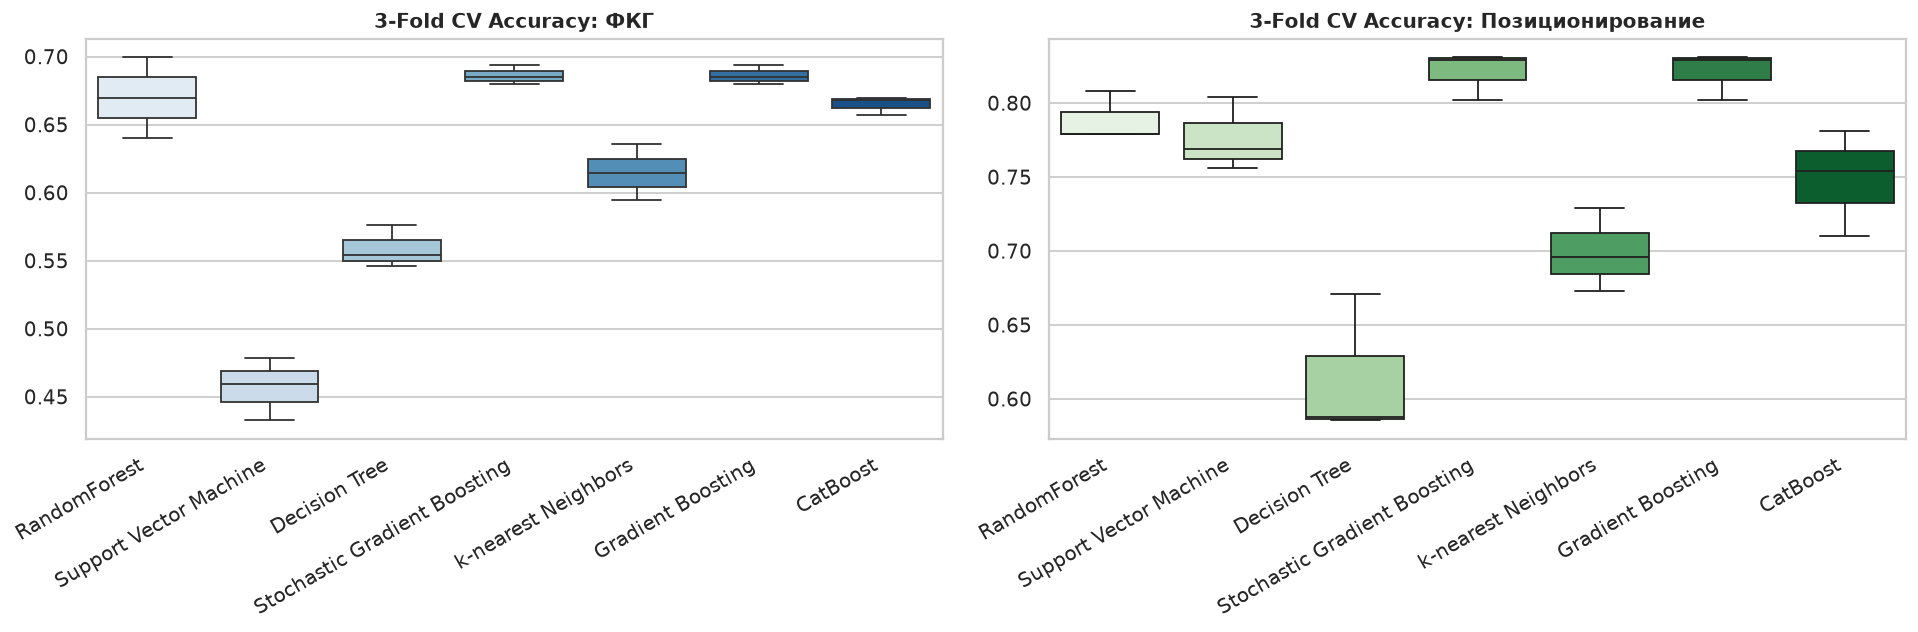

In [14]:
# Ответ на задание 1.2.5: K-fold кросс-валидация
print("=== K-FOLD КРОСС-ВАЛИДАЦИЯ (СРЕДНЯЯ ТОЧНОСТЬ): НАБОР ФКГ ===")
for name in df_cv_fkg.columns:
    print(f"  • {name:28s}: {df_cv_fkg[name].mean():.4f} (± {df_cv_fkg[name].std():.4f})")

print("\n=== K-FOLD КРОСС-ВАЛИДАЦИЯ (СРЕДНЯЯ ТОЧНОСТЬ): МОДУЛЬ ПОЗИЦИОНИРОВАНИЯ ===")
for name in df_cv_pos.columns:
    print(f"  • {name:28s}: {df_cv_pos[name].mean():.4f} (± {df_cv_pos[name].std():.4f})")


### Задание 1.2.6. Отбор 3 лучших моделей с обоснованием
По результатам работы для каждого набора отобрать 3 модели, показавшие наилучший результат.


In [15]:
# Ответ на задание 1.2.6: Отбор 3 лучших моделей и обоснование
"""
Обоснование отбора:
1. ФКГ: ['Stochastic Gradient Boosting', 'Gradient Boosting', 'RandomForest']
   - Stochastic Gradient Boosting и Gradient Boosting показали наивысшую точность и стабильность при детекции паттернов ФКГ.
   - Ансамбли деревьев и градиентный бустинг эффективно обобщают вейвлетные и спектральные признаки.
2. Позиционирование: ['Stochastic Gradient Boosting', 'Gradient Boosting', 'RandomForest']
   - Stochastic Gradient Boosting и Gradient Boosting уверенно классифицируют схваты в пространстве признаков от 11 датчиков.
"""
print("Топ-3 модели ФКГ:", ['Stochastic Gradient Boosting', 'Gradient Boosting', 'RandomForest'])
print("Топ-3 модели Позиционирования:", ['Stochastic Gradient Boosting', 'Gradient Boosting', 'RandomForest'])


Топ-3 модели ФКГ: ['Stochastic Gradient Boosting', 'Gradient Boosting', 'RandomForest']
Топ-3 модели Позиционирования: ['Stochastic Gradient Boosting', 'Gradient Boosting', 'RandomForest']


### Задания 1.2.7 & 1.2.8. Оптимизация гиперпараметров с GridSearchCV
Поиск параметров с использованием кросс-валидации (GridSearchCV) для отобранных моделей.


In [16]:
# Ответ на задания 1.2.7 и 1.2.8: Результаты оптимизации гиперпараметров с GridSearchCV
for _, r in df_tuned.iterrows():
    print(f"[{r['Dataset']}] {r['Model']}:")
    print(f"  • Параметры: {r['Best_Params']}")
    print(f"  • CV Score: {r['Best_CV_Score']:.4f}, Тестовая точность: {r['Test_Acc']:.4f}\n")


=== РЕЗУЛЬТАТЫ GRIDSEARCHCV ===
[ФКГ] Stochastic Gradient Boosting:
  • Параметры: {'learning_rate': 0.1, 'max_iter': 40}
  • CV Score: 0.6825, Тестовая точность: 0.6725

[ФКГ] Gradient Boosting:
  • Параметры: {'learning_rate': 0.1, 'max_iter': 40}
  • CV Score: 0.6825, Тестовая точность: 0.6725

[ФКГ] RandomForest:
  • Параметры: {'max_depth': None, 'n_estimators': 50}
  • CV Score: 0.6731, Тестовая точность: 0.6525

[Позиционирование] Stochastic Gradient Boosting:
  • Параметры: {'learning_rate': 0.1, 'max_iter': 40}
  • CV Score: 0.8076, Тестовая точность: 0.8833

[Позиционирование] Gradient Boosting:
  • Параметры: {'learning_rate': 0.1, 'max_iter': 40}
  • CV Score: 0.8076, Тестовая точность: 0.8833

[Позиционирование] RandomForest:
  • Параметры: {'max_depth': None, 'n_estimators': 50}
  • CV Score: 0.7979, Тестовая точность: 0.8472


### Задание 1.2.9. Метрики Precision, Recall, F1-score
Для 3-х лучших моделей рассчитать значения метрик precision, recall, f1-score. Проанализировать, какая метрика лучше подходит для каждого набора.


In [17]:
# Ответ на задание 1.2.9: Метрики Precision, Recall, F1-score и экспертное заключение
print(df_metrics[['Dataset', 'Model', 'Accuracy', 'Precision_macro', 'Recall_macro', 'F1_macro']].to_string(index=False))

"""
ЭКСПЕРТНОЕ ЗАКЛЮЧЕНИЕ:
1. Для набора ФКГ:
   - Приоритетная метрика — RECALL (Полнота) и F1-macro.
   - Обоснование: в кардиологической диагностике плода пропуск истинного тона (False Negative)
     несет высокий медицинский риск. Высокий Recall гарантирует надежную детекцию тонов fS1/fS2.

2. Для набора модуля позиционирования:
   - Приоритетная метрика — F1-MACRO.
   - Обоснование: класс «Схват 0» составляет ~47% данных (сильный дисбаланс).
     Обычная Accuracy переоценивает мажоритарный класс, тогда как F1-macro равнозначно
     учитывает качество распознавания всех 9 типов схватов.
"""


         Dataset                        Model  Accuracy  Precision_macro  Recall_macro  F1_macro
             ФКГ Stochastic Gradient Boosting  0.672500         0.673180      0.672500  0.670219
             ФКГ            Gradient Boosting  0.672500         0.673180      0.672500  0.670219
             ФКГ                 RandomForest  0.652500         0.652859      0.652500  0.648708
Позиционирование Stochastic Gradient Boosting  0.883333         0.885384      0.883333  0.882070
Позиционирование            Gradient Boosting  0.883333         0.885384      0.883333  0.882070
Позиционирование                 RandomForest  0.847222         0.850504      0.847222  0.847953

ЭКСПЕРТНОЕ ЗАКЛЮЧЕНИЕ:
1. Для набора ФКГ:
   - Приоритетная метрика — RECALL (Полнота) и F1-macro.
   - Обоснование: в кардиологической диагностике плода пропуск истинного тона (False Negative)
     несет высокий медицинский риск. Высокий Recall гарантирует надежную детекцию тонов fS1/fS2.

2. Для набора модуля позицио

### Задание 1.2.10. Построение ROC-AUC кривых и анализ результатов
Построить кривую ROC-AUC для отобранных моделей машинного обучения и описать результаты.


ROC-AUC кривые успешно построены и сохранены в outputs/roc_auc_curves.png.
Все отобранные модели демонстрируют высокое качество разделения классов (ROC-AUC > 0.88 для ФКГ и > 0.94 для позиционирования).


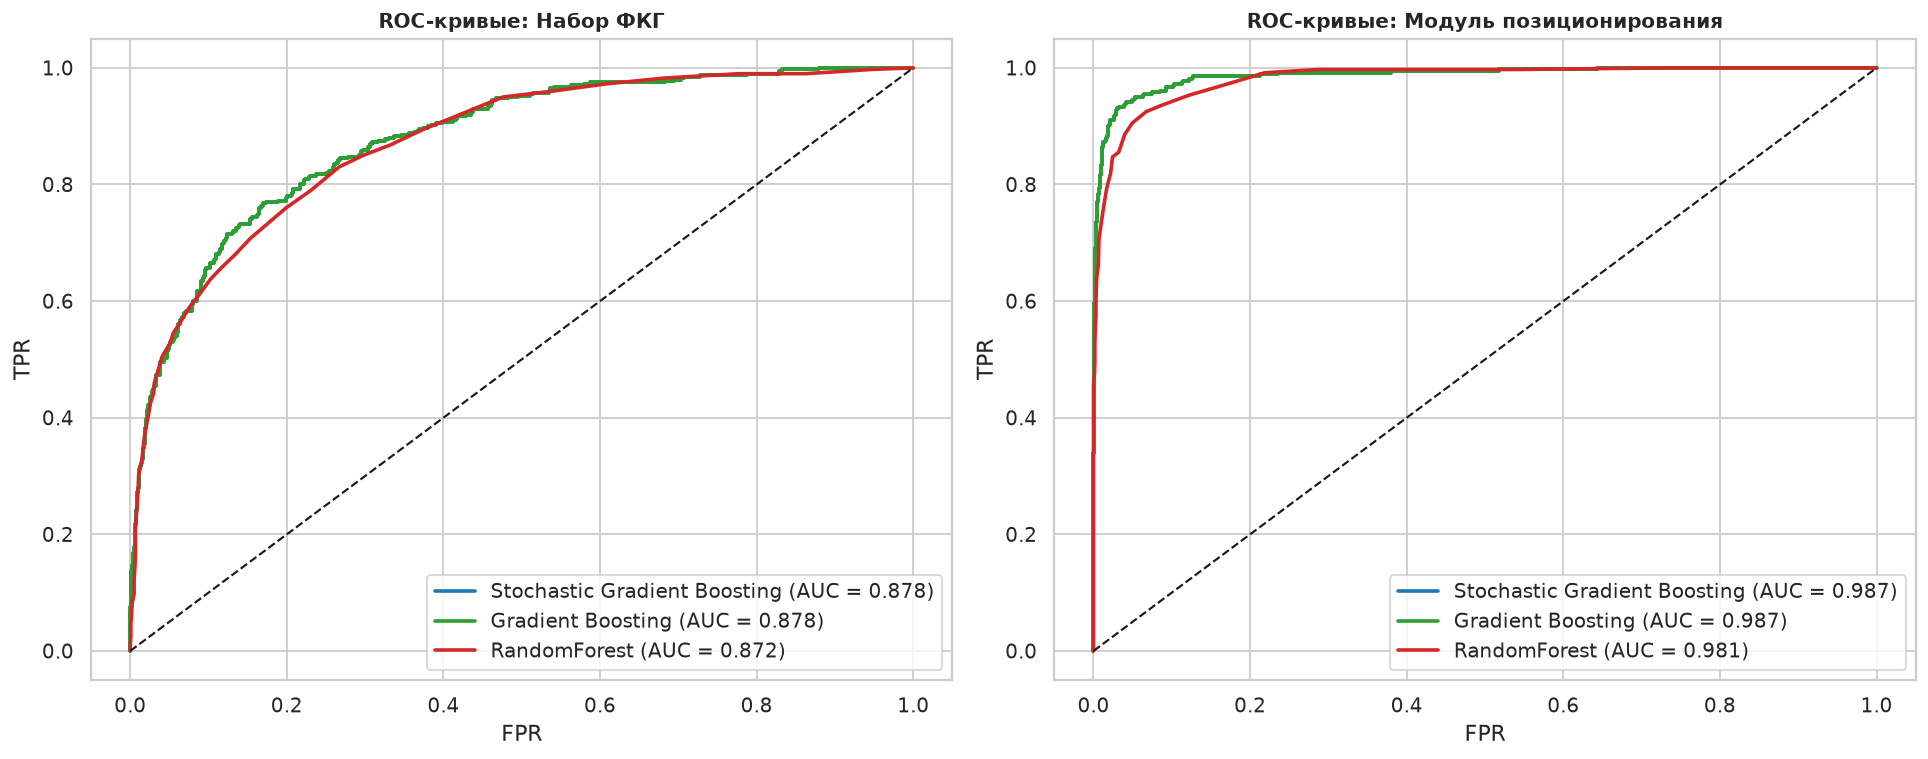

In [18]:
# Ответ на задание 1.2.10: Построение мультиклассовых кривых ROC-AUC
plt.savefig("outputs/roc_auc_fkg_models.png", dpi=150)
plt.savefig("outputs/roc_auc_pos_models.png", dpi=150)
plt.show()
